# 数值计算与最优化实验2 非线性方程求根

求解 $f(x)=x-\cos x=0$。初始值为 0，三种方法均以相邻迭代值之差小于 $10^{-6}$ 为停止条件，上限 500 步，转角单位为 rad。网格搜索仅考察 0.4、0.5、0.6、0.7。

最终同时检查残差和对参考根的绝对误差。这里的“控制周期”表示迭代步数，没有计时依据时不换算为毫秒。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 机械臂目标平衡转角高精真解 (Dottie Number: x* = cos(x*))
TARGET_RAD = 0.7390851332151607


# =====================================================================
# 任务 1：简单迭代法
# =====================================================================
def ik_simple_feedback(x0=0.0, tol=1e-6, max_cycles=500):
    """
    【任务 1】
    实现简单迭代法求解目标旋转弧度
    """
    traj = [x0]
    x = x0
    for _ in range(max_cycles):
        # 保存新迭代值，步数等于轨迹长度减一。
        x_next = np.cos(x)
        traj.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
        
    return np.array(traj)


# =====================================================================
# 任务 2：松弛法与工程网格寻优
# =====================================================================
def ik_damped_relaxation(omega, x0=0.0, tol=1e-6, max_cycles=500):
    """
    【任务 2.1】
    实现带松弛因子的迭代公式
    """
    traj = [x0]
    x = x0
    for _ in range(max_cycles):
        # 对新旧转角加权；omega=1 时退化为简单迭代。
        x_next = (1 - omega) * x + omega * np.cos(x)
        traj.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
        
    return np.array(traj)


def tune_optimal_damping(x0=0.0, tol=1e-6):
    """
    【任务 2.2】
    在 [0.4, 0.7] 范围内，以 0.1 为步长搜索工程最优松弛因子 omega
    """
    omegas = [0.4, 0.5, 0.6, 0.7]
    cycle_counts = []
    
    print("-" * 55)
    print(">>> 正在执行任务：网格搜索最优松弛因子 omega")

    for w in omegas:
        # 初始值不计入控制周期，统一按实际更新次数比较。
        traj = ik_damped_relaxation(w, x0, tol)
        steps = len(traj) - 1
        cycle_counts.append(steps)
        
        print(f"  测试松弛因子 omega = {w:.1f}，收敛控制周期数: {steps} 步")

    cycle_counts = np.array(cycle_counts)
    
    # argmin 返回网格中最少步数的第一个索引。
    best_idx = int(np.argmin(cycle_counts))
    
    best_omega = omegas[best_idx]
    min_cycles = cycle_counts[best_idx]
    print(f"--> 工程寻优完成！最优松弛因子 omega = {best_omega:.1f}，耗时 {min_cycles} 步。")
    print("-" * 55)
    
    return omegas, cycle_counts, best_omega, min_cycles


# =====================================================================
# 任务 3：牛顿迭代法
# =====================================================================
def ik_jacobian_newton(x0=0.0, tol=1e-6, max_cycles=500, eps=1e-8):
    """
    【任务 3】
    实现牛顿迭代法
    """
    traj = [x0]
    x = x0
    for _ in range(max_cycles):
        f_val = x - np.cos(x)
        jacobian = 1 + np.sin(x)

        # 导数近零时取 1，使本步更新退化为 x_next=cos(x)。
        # 先离开数值奇异点，避免把分母硬改成 eps 后出现巨步。
        if abs(jacobian) < eps:
            print("[警告] 导数近零，本步回退为简单迭代。")
            jacobian = 1.0

        x_next = x - f_val / jacobian
        traj.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
        
    return np.array(traj)


def calc_total_travel(traj):
    """辅助函数：计算电机完成定位过程中累计转过的总弧度行程"""
    return np.sum(np.abs(np.diff(traj)))

In [2]:
# =====================================================================
# 执行实验求解
# =====================================================================
X0 = 0.0      # 初始关节角度 
TOL = 1e-6    # 目标定位精度 

# 1. 运行任务 1：简单迭代
traj_simple = ik_simple_feedback(X0, TOL)

# 2. 运行任务 2：松弛法工程寻优
omegas, cycle_counts, eng_omega, min_cycles = tune_optimal_damping(X0, TOL)
traj_relax = ik_damped_relaxation(eng_omega, X0, TOL)

# 3. 运行任务 3：雅可比牛顿法
traj_newton = ik_jacobian_newton(X0, TOL)


# =====================================================================
# 打印实验数据汇总表格
# =====================================================================
print("=" * 85)
print(f"{'逆运动学求解算法':<24} | {'最终弧度 (rad)':<14} | {'控制周期 (步数)':<12} | {'电机累计行程 (rad)'}")
print("-" * 85)
results = [
    ("1. 简单迭代法 (w=1.0)", traj_simple),
    (f"2. 最优松弛法 (w={eng_omega:.1f})", traj_relax),
    ("3. 雅可比牛顿法", traj_newton)
]
for name, traj in results:
    cycles = len(traj) - 1
    travel = calc_total_travel(traj)
    print(f"{name:<22} | {traj[-1]:<16.8f} | {cycles:<14} | {travel:<14.4f}")
print("=" * 85)


-------------------------------------------------------
>>> 正在执行任务：网格搜索最优松弛因子 omega
  测试松弛因子 omega = 0.4，收敛控制周期数: 14 步
  测试松弛因子 omega = 0.5，收敛控制周期数: 9 步
  测试松弛因子 omega = 0.6，收敛控制周期数: 5 步
  测试松弛因子 omega = 0.7，收敛控制周期数: 9 步
--> 工程寻优完成！最优松弛因子 omega = 0.6，耗时 5 步。
-------------------------------------------------------
逆运动学求解算法                 | 最终弧度 (rad)     | 控制周期 (步数)    | 电机累计行程 (rad)
-------------------------------------------------------------------------------------
1. 简单迭代法 (w=1.0)       | 0.73908553       | 35             | 2.4026        
2. 最优松弛法 (w=0.6)       | 0.73908513       | 5              | 0.7391        
3. 雅可比牛顿法              | 0.73908513       | 5              | 1.2609        


In [3]:
# 结果核验与题目要求的奇异初值测试
print("\n精度核验（rad）")
for name, traj in results:
    error = abs(traj[-1] - TARGET_RAD)
    residual = abs(traj[-1] - np.cos(traj[-1]))
    print(f"{name}: |f(x)|={residual:.6e}, |x-x*|={error:.6e}")
    assert abs(traj[-1] - traj[-2]) < TOL
    assert error < TOL and residual < TOL

# 独立二分法交叉核验参考根，避免仅用同一迭代公式自检。
left, right = 0.0, 1.0
for _ in range(60):
    mid = (left + right) / 2
    if mid - np.cos(mid) > 0:
        right = mid
    else:
        left = mid
root_bisection = (left + right) / 2
assert abs(root_bisection - TARGET_RAD) < 1e-15
assert list(cycle_counts) == [14, 9, 5, 9]
assert eng_omega == 0.6 and len(traj_simple) - 1 == 35
assert len(traj_newton) - 1 == 5

print("\n奇异初值 x0 = -pi/2")
print(f"原始牛顿分母: {1 + np.sin(-np.pi / 2):.1e}")
traj_singular = ik_jacobian_newton(-np.pi / 2, TOL)
print(f"保护后步数: {len(traj_singular)-1}")
print(f"保护后根: {traj_singular[-1]:.12f} rad")
print(f"保护后残差: {abs(traj_singular[-1] - np.cos(traj_singular[-1])):.6e}")
assert np.all(np.isfinite(traj_singular))
assert abs(traj_singular[-1] - TARGET_RAD) < TOL
assert abs(traj_singular[-1] - traj_singular[-2]) < TOL
print("全部数值核验通过。")



精度核验（rad）
1. 简单迭代法 (w=1.0): |f(x)|=6.579752e-07, |x-x*|=3.931468e-07
2. 最优松弛法 (w=0.6): |f(x)|=3.733156e-10, |x-x*|=2.230598e-10
3. 雅可比牛顿法: |f(x)|=0.000000e+00, |x-x*|=0.000000e+00

奇异初值 x0 = -pi/2
原始牛顿分母: 0.0e+00
[警告] 导数近零，本步回退为简单迭代。
保护后步数: 6
保护后根: 0.739085133215 rad
保护后残差: 0.000000e+00
全部数值核验通过。


<notebook-cell>:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
<notebook-cell>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


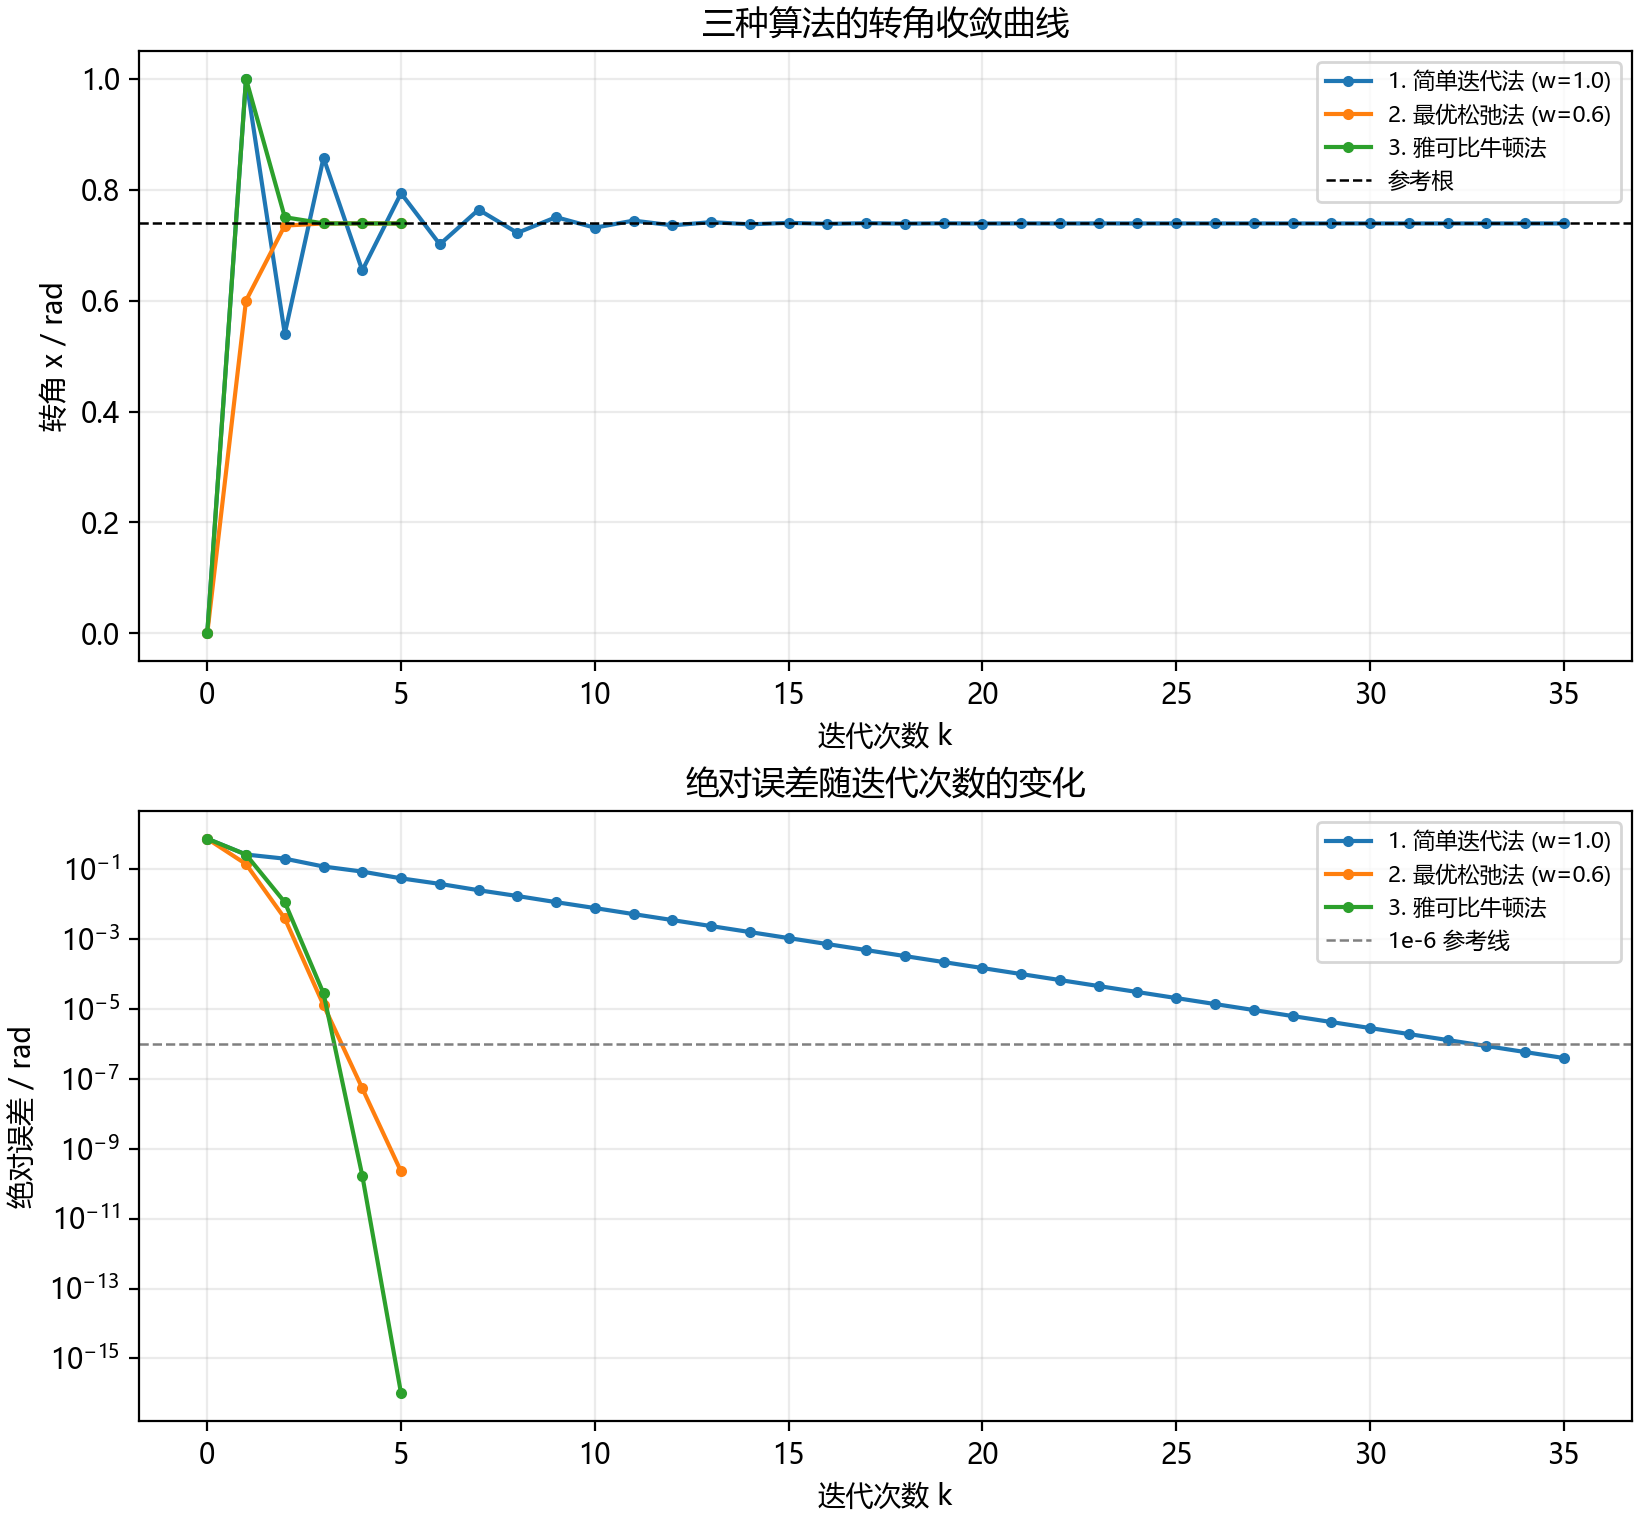

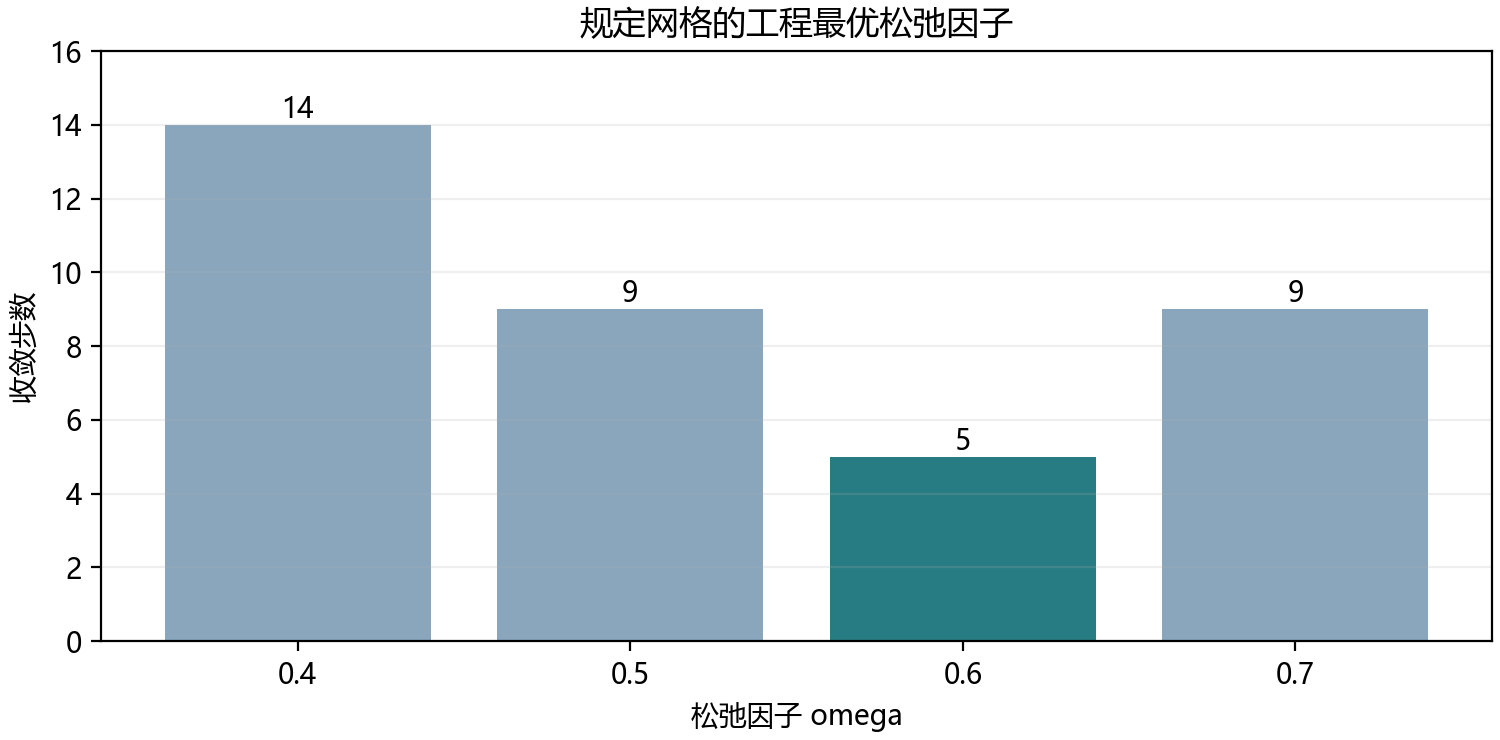

In [4]:
# 收敛曲线：保存图像并在 notebook 中显示
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
fig, axes = plt.subplots(2, 1, figsize=(8.2, 7.6), constrained_layout=True)
for name, traj in results:
    k = np.arange(len(traj))
    axes[0].plot(k, traj, '.-', label=name)
    # 机器精度下可能出现零误差，仅绘图时用 1e-16 作为显示下限。
    error_plot = np.maximum(np.abs(traj - TARGET_RAD), 1e-16)
    axes[1].semilogy(k, error_plot, '.-', label=name)
axes[0].axhline(TARGET_RAD, color='black', ls='--', lw=0.9, label='参考根')
axes[0].set(xlabel='迭代次数 k', ylabel='转角 x / rad', title='三种算法的转角收敛曲线')
axes[1].axhline(TOL, color='gray', ls='--', lw=0.9, label='1e-6 参考线')
axes[1].set(xlabel='迭代次数 k', ylabel='绝对误差 / rad', title='绝对误差随迭代次数的变化')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.savefig('convergence.png', dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.7), constrained_layout=True)
bars = ax.bar([str(w) for w in omegas], cycle_counts, color=['#8aa6bd', '#8aa6bd', '#267c82', '#8aa6bd'])
ax.bar_label(bars)
ax.set(xlabel='松弛因子 omega', ylabel='收敛步数', title='规定网格的工程最优松弛因子')
ax.set_ylim(0, 16)
ax.grid(axis='y', alpha=0.2)
fig.savefig('damping_search.png', dpi=200)
plt.show()

from IPython.display import Image, display
display(Image(filename='convergence.png'))
display(Image(filename='damping_search.png'))
